In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from analysis import statistik, sjukdomsandel, konfidensintervall, hypotesprovning, HealthAnalyzer

df = pd.read_csv("health_study_dataset.csv")
analys = HealthAnalyzer(df)
np.random.seed(42)


In [2]:
display(df.head())
df.info()
print(df.shape)

df.duplicated().sum()
df.isna().sum()
display(analys.statistik())

df["sex"].value_counts()       
df["smoker"].value_counts()       
df["disease"].value_counts()  

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB
(800, 9)


,age,weight,height,systolic_bp,cholesterol
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,49.426250,73.413000,171.849250,149.178625,4.929150
std,14.501118,13.685059,9.804259,12.793360,0.848413
min,18.000000,33.700000,144.400000,106.800000,2.500000
25%,39.000000,64.800000,164.775000,140.900000,4.327500
50%,50.000000,73.200000,171.350000,149.400000,4.970000
75%,59.000000,82.600000,178.925000,157.600000,5.482500
max,90.000000,114.400000,200.400000,185.900000,7.880000


disease
0    753
1     47
Name: count, dtype: int64

In [3]:
kolumner = ["age", "weight", "height", "systolic_bp", "cholesterol"]
df[kolumner].describe()

,age,weight,height,systolic_bp,cholesterol
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,49.426250,73.413000,171.849250,149.178625,4.929150
std,14.501118,13.685059,9.804259,12.793360,0.848413
min,18.000000,33.700000,144.400000,106.800000,2.500000
25%,39.000000,64.800000,164.775000,140.900000,4.327500
50%,50.000000,73.200000,171.350000,149.400000,4.970000
75%,59.000000,82.600000,178.925000,157.600000,5.482500
max,90.000000,114.400000,200.400000,185.900000,7.880000


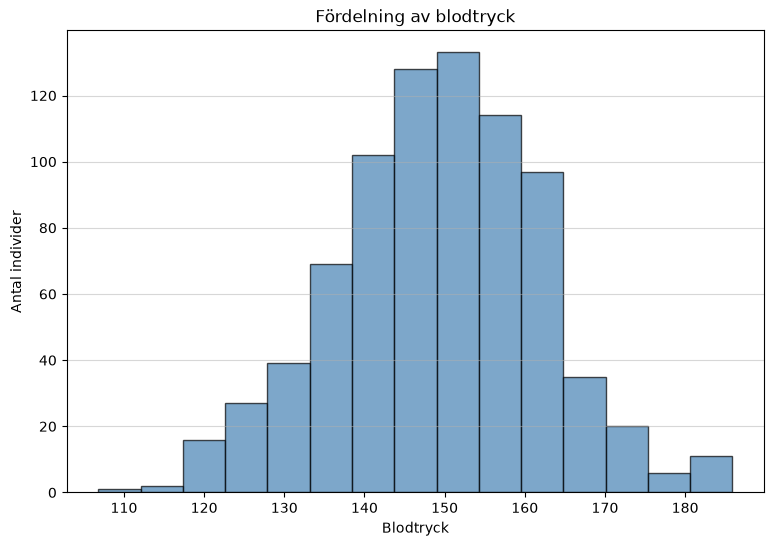

Histogrammet ger en översikt över hur blodtrycket är fördelat bland deltagarna och vilka blodtrycksvärden som är vanligast. De flesta ligger runt 140–160 mmHg, och färre har väldigt lågt eller högt blodtryck.


In [4]:
plt.figure(figsize=(9,6))
plt.hist(df["systolic_bp"], bins=15, color='steelblue', edgecolor='black', alpha=0.7)
plt.title("Fördelning av blodtryck")
plt.xlabel("Blodtryck")
plt.ylabel("Antal individer")
plt.grid(True, axis='y', alpha=0.5)
plt.show()

print("Histogrammet ger en översikt över hur blodtrycket är fördelat bland deltagarna och " \
"vilka blodtrycksvärden som är vanligast. De flesta ligger runt 140–160 mmHg," \
" och färre har väldigt lågt eller högt blodtryck.")

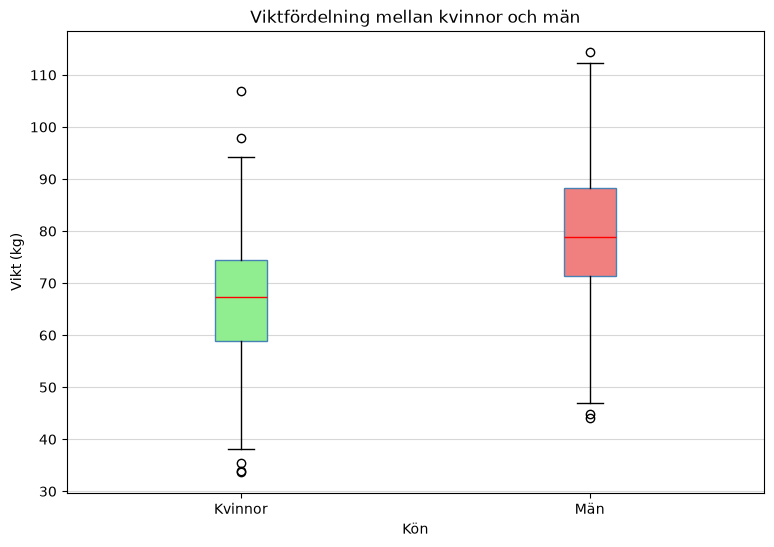

Boxplot diagrammet visar viktfördelningen mellan kvinnor och män samt skillnader i median och spridning. Männen väger generellt mer, med en median på ungefär 79 kg jämfört med 67 kg för kvinnorna. Vi kan också se några avvikande värden i båda grupperna.


In [5]:
kvinnor = df[df["sex"]=="F"]["weight"]
man = df[df["sex"]=="M"]["weight"]

plt.figure(figsize=(9,6))
box = plt.boxplot(
    [kvinnor, man],
    tick_labels=["Kvinnor", "Män"],
    patch_artist=True,
    boxprops=dict(color='steelblue'),
    medianprops=dict(color='red')
)
box["boxes"][0].set_facecolor('lightgreen')
box["boxes"][1].set_facecolor('lightcoral')

plt.title("Viktfördelning mellan kvinnor och män")
plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")
plt.grid(True, axis='y', alpha=0.5)
plt.show()

print("Boxplot diagrammet visar viktfördelningen mellan kvinnor och män samt skillnader i median och spridning." \
" Männen väger generellt mer, med en median på ungefär 79 kg jämfört med 67 kg för kvinnorna. Vi kan också se några avvikande värden i båda grupperna.")

Andel rökare: 26.62%
Andel icke-rökare: 73.38%


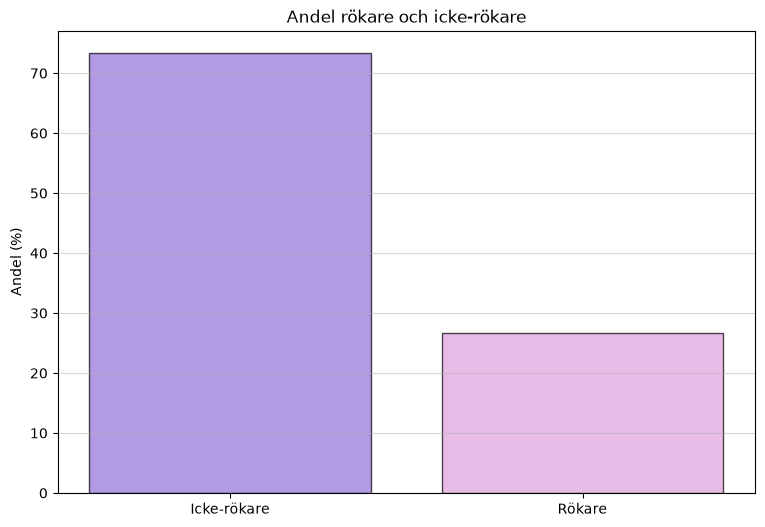

Stapeldiagrammet visar hur stor andel av deltagarna som röker och inte röker i procent. Ungefär 27 % är rökare och 73 % är icke-rökare.


In [6]:
andel_rokare = df["smoker"].value_counts(normalize=True) * 100
print(f"Andel rökare: {andel_rokare['Yes']:.2f}%")
print(f"Andel icke-rökare: {andel_rokare['No']:.2f}%")

plt.figure(figsize=(9,6))
plt.bar(["Icke-rökare", "Rökare"], [andel_rokare['No'], andel_rokare['Yes']], 
color=['mediumpurple', 'plum'], edgecolor='black', alpha=0.7)
plt.title("Andel rökare och icke-rökare")
plt.ylabel("Andel (%)")
plt.grid(axis='y', alpha=0.5)
plt.show()

print("Stapeldiagrammet visar hur stor andel av deltagarna som röker och inte röker i procent." \
" Ungefär 27 % är rökare och 73 % är icke-rökare.")

In [7]:
print(f"Antal med sjukdom: {df['disease'].sum()}")

andel_sjukdom = sjukdomsandel(df)
print(f"Andel med sjukdom: {andel_sjukdom * 100:.2f}%")

np.random.seed(42)
sjuk = andel_sjukdom
frisk = 1 - sjuk
simulering = np.random.choice([0, 1], size=1000, p=[frisk, sjuk])

sumulerad_andel = simulering.mean()

print(f"\nVerklig andel: {andel_sjukdom * 100:.2f}%")
print(f"Simulerad andel: {sumulerad_andel * 100:.2f}%")
diff = (andel_sjukdom - sumulerad_andel) * 100
print(f"\nSkillnad mellan verklig och simulerad andel: {diff:.2f} procentenheter")

print(f"\nDen verkliga andelen visar att 5,88 % av deltagarna har sjukdomen, och den simulerade andelen blev 5,60 %." \
f" Resultaten ligger väldigt nära varandra och den lilla skillnaden beror på slumpen.")


Antal med sjukdom: 47
Andel med sjukdom: 5.88%

Verklig andel: 5.88%
Simulerad andel: 5.60%

Skillnad mellan verklig och simulerad andel: 0.27 procentenheter

Den verkliga andelen visar att 5,88 % av deltagarna har sjukdomen, och den simulerade andelen blev 5,60 %. Resultaten ligger väldigt nära varandra och den lilla skillnaden beror på slumpen.


In [8]:
blodtryck = df["systolic_bp"]

mean, nedre_grans, ovre_grans = analys.konfidensintervall("systolic_bp")
print(f"Medelvärde blodtryck: {mean:.2f}")

print(f"95 % konfidensintervall (normalapproximation): {nedre_grans:.2f} – {ovre_grans:.2f} mmHg")

print("\nMedelvärdet för blodtrycket är 149,18 mmHg. Med 95 % konfidensintervall på 148,29–150,07 mmHg " \
"uppskattar vi att populationens verkliga medelvärde ligger inom det intervallet.")

Medelvärde blodtryck: 149.18
95 % konfidensintervall (normalapproximation): 148.29 – 150.07 mmHg

Medelvärdet för blodtrycket är 149,18 mmHg. Med 95 % konfidensintervall på 148,29–150,07 mmHg uppskattar vi att populationens verkliga medelvärde ligger inom det intervallet.


In [9]:
np.random.seed(42)
bootstrap_means = []

for i in range(2000):
    stickprov_bootstrap = np.random.choice(blodtryck, size=800, replace=True)
    stickprov_mean = stickprov_bootstrap.mean()
    bootstrap_means.append(stickprov_mean)


nedre_bootstrap = np.percentile(bootstrap_means, 2.5)
ovre_bootstrap = np.percentile(bootstrap_means, 97.5)

print(f"95 % konfidensintervall (bootstrap): {nedre_bootstrap:.2f} – {ovre_bootstrap:.2f} mmHg")

skillnad_nedre = nedre_grans - nedre_bootstrap
skillnad_ovre = ovre_grans - ovre_bootstrap
print(f"\nSkillnad mellan normalapproximation och bootstrap (nedre): {skillnad_nedre:.2f} mmHg")
print(f"Skillnad mellan normalapproximation och bootstrap (övre): {skillnad_ovre:.2f} mmHg")


95 % konfidensintervall (bootstrap): 148.31 – 150.10 mmHg

Skillnad mellan normalapproximation och bootstrap (nedre): -0.02 mmHg
Skillnad mellan normalapproximation och bootstrap (övre): -0.04 mmHg


### Jämförelse av konfidensintervall
Jag använder två metoder för att beräkna 95 % konfidensintervall för det genomsnittliga blodtrycket.

Normalapproximation passar eftersom vi har ett stort stickprov med 800 deltagare. Metoden använder medelvärde och standardfel för att uppskatta osäkerheten kring medelvärdet.

Bootstrap används som en andra metod och bygger på 2 000 slumpmässiga stickprov med återläggning. På så sätt kan vi se hur mycket medelvärdet kan variera.

Båda metoderna gav väldigt liknande konfidensintervall, med bara små skillnader mellan gränserna. Det betyder att vår uppskattning av osäkerheten är ganska stabil.

In [10]:
from scipy.stats import ttest_ind

# Hypotesprövning – rökare och icke-rökare
rokare = df.loc[df["smoker"] == "Yes", "systolic_bp"]
icke_rokare = df.loc[df["smoker"] == "No", "systolic_bp"]

print("Rökare:", rokare.mean())
print("Icke-rökare:", icke_rokare.mean())

alpha = 0.05

t_stat, p_value = hypotesprovning(rokare, icke_rokare)

print("t-statistik:", t_stat)
print("p-värde:", p_value)

if p_value < alpha:
    print("Förkasta H0")
else:
    print("Förkasta inte H0")


# Power-simulering
antal_rokare = len(rokare)
antal_icke_rokare = len(icke_rokare)

print("Rökare:", antal_rokare)
print("Icke-rökare:", antal_icke_rokare)

std = icke_rokare.std()
print("Standardavvikelse:", std)

skillnad = 5  # testar om man kan upptäcka 5 mmHg högre blodtryck hos rökare
antal_simuleringar = 1000
signifikanta = 0

np.random.seed(42)

for i in range(antal_simuleringar):
    simulering_rokare = np.random.normal(
        loc=icke_rokare.mean() + skillnad,
        scale=std,
        size=antal_rokare
    )

    simulering_icke_rokare = np.random.normal(
        loc=icke_rokare.mean(),
        scale=std,
        size=antal_icke_rokare
    )

    t_stat, p_sim = ttest_ind(
        simulering_rokare,
        simulering_icke_rokare,
        equal_var=False,
        alternative="greater"
    )

    if p_sim < alpha:
        signifikanta += 1

power = signifikanta / antal_simuleringar

print("Power:", round(power * 100, 2), "%")

Rökare: 149.524882629108
Icke-rökare: 149.05298126064736
t-statistik: 0.4503433193393224
p-värde: 0.32636693716994986
Förkasta inte H0
Rökare: 213
Icke-rökare: 587
Standardavvikelse: 12.626037772560291
Power: 100.0 %


### Hypotesprövning – Rökare och blodtryck

Jag använde Welch t-test för att undersöka om rökare har högre blodtryck än icke-rökare.

Rökarna hade ett medelvärde på 149,52 mmHg och icke-rökarna 149,05 mmHg. Det var alltså en väldigt liten skillnad på bara 0,47 mmHg.

P-värdet blev 0,326, vilket är högre än 0,05. Därför förkastar vi inte nollhypotesen.

Resultatet är inte statistiskt signifikant. Rökarna hade lite högre blodtryck, men skillnaden kan bero på slumpen. Därför kan vi inte säga säkert att rökare har högre blodtryck än icke-rökare.

### Power-simulering

Jag gjorde 1 000 simuleringar för att se om t-testet kan upptäcka en skillnad på 5 mmHg mellan rökare och icke-rökare.

Resultatet blev 100 % power, vilket betyder att testet upptäckte skillnaden varje gång. Det visar att testet har hög statistisk styrka för just den skillnaden.

### Val av metod

Jag valde Welch t-test eftersom jag ville jämföra medelblodtrycket mellan två oberoende grupper, rökare och icke-rökare. Grupperna har olika många deltagare och kan ha olika spridning, därför passar Welch t-test bra.

Jag använde också bootstrap för att jämföra konfidensintervallet med normalapproximation och se om metoderna gav liknande resultat.

### Källor

- Welch t-test:
- https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html
- https://en.wikipedia.org/wiki/Welch%27s_t-test


- Bootstrap:
- https://docs.scipy.org/doc/scipy-1.18.0/reference/generated/scipy.stats.bootstrap.html
- https://en.wikipedia.org/wiki/Bootstrapping_%28statistics%29


- Normalfördelning:
- https://numpy.org/doc/2.1/reference/random/generated/numpy.random.normal.html
- https://en.wikipedia.org/wiki/Normal_distribution



# Del 2. Fördjupning och pipeline

### Enkel linjär regression

Jag använder enkel linjär regression för att undersöka
sambandet mellan ålder och blodtryck.

Ålder (X) är den oberoende variabeln och blodtryck (y)
är den beroende variabeln.

Syftet är att undersöka om äldre personer tenderar
att ha högre blodtryck och hur stor del av variationen
i blodtrycket som modellen kan förklara med hjälp av ålder.

In [11]:
# Enkel linjär regression 
y_pred, r2, skarning, lutning = analys.enkel_regression()
print("Förklaringsgrad: ",round(r2 * 100, 2), "%")

Förklaringsgrad:  36.92 %


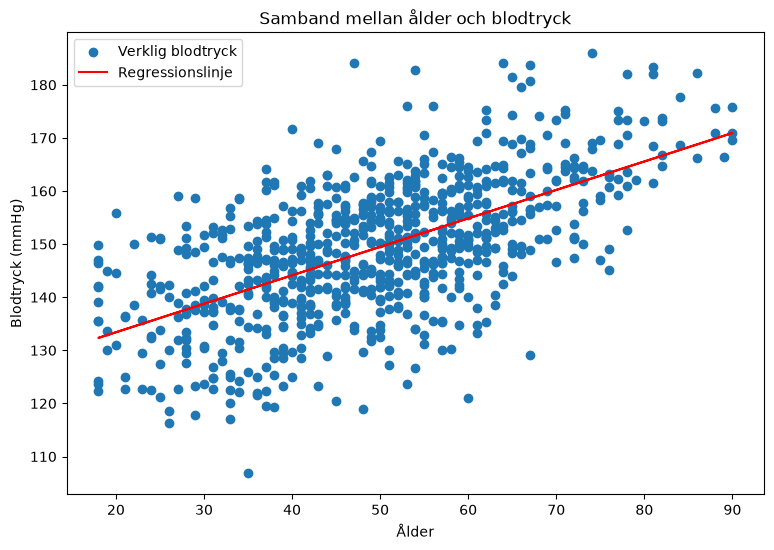

En åldersskillnad på 10 år motsvarar enligt modellen 5.36 mmHg högre blodtryck.


In [12]:
plt.figure(figsize=(9, 6))
plt.scatter(df["age"], df["systolic_bp"], label="Verklig blodtryck")
plt.plot(df["age"], y_pred, color="red", label="Regressionslinje")
plt.title("Samband mellan ålder och blodtryck")
plt.xlabel("Ålder")
plt.ylabel("Blodtryck (mmHg)")
plt.legend()
plt.show()

print(f"En åldersskillnad på 10 år motsvarar enligt modellen {10 * lutning:.2f} mmHg högre blodtryck.")

### Tolkning

Resultatet visar ett positivt samband mellan ålder och blodtryck.
En åldersskillnad på 10 år motsvarar enligt modellen 5,36 mmHg högre blodtryck.

Modellen förklarar 36,92 % av variationen i blodtrycket med hjälp av ålder.
Sambandet innebär inte nödvändigtvis ett orsakssamband.

_________________________________________________________________________________

### Multipel linjär regression

Jag använder multipel linjär regression för att undersöka
sambandet mellan blodtryck och tre oberoende variabler:
ålder, vikt och kolesterol.

Syftet är att undersöka om modellen kan förklara en större
del av variationen i blodtrycket när fler variabler inkluderas.

In [13]:
# Multipel linjär regression 
y_pred_multipel, r2_multipel = analys.multipel_regression()
print("Förklingsgrad av blodtryck utifrån ålder, vikt och kolesterol: ",
      round(r2_multipel * 100, 2), "%")

Förklingsgrad av blodtryck utifrån ålder, vikt och kolesterol:  40.58 %


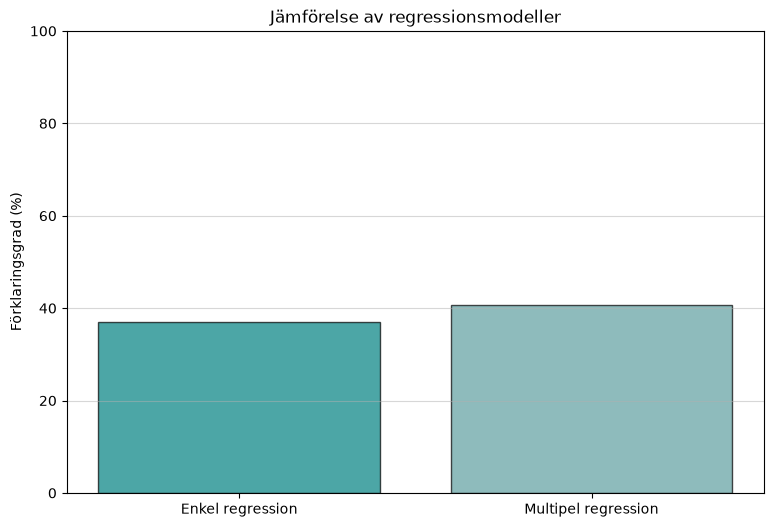

Enkel regression: 36.92%
Multipel regression: 40.58%
Förklaringsgraden ökar med 3.67 procentenheter när vikt och kolesterol inkluderas i modellen.


In [14]:
plt.figure(figsize=(9, 6))
plt.bar(["Enkel regression", "Multipel regression"], [r2 * 100, r2_multipel * 100], 
        color=['teal', 'cadetblue'], edgecolor='black', alpha=0.7)
plt.title("Jämförelse av regressionsmodeller")
plt.ylabel("Förklaringsgrad (%)")
plt.grid(axis='y', alpha=0.5)
plt.ylim(0, 100)
plt.show()

print(f"Enkel regression: {r2 * 100:.2f}%")
print(f"Multipel regression: {r2_multipel * 100:.2f}%")

diff = r2_multipel - r2
print(f"Förklaringsgraden ökar med {diff * 100:.2f} procentenheter när vikt och kolesterol inkluderas i modellen.")


### Tolkning

När vikt och kolesterol inkluderas ökar förklaringsgraden
från 36,92 % till 40,58 %, ökning med cirka 3,67 procentenheter.

Den multipla modellen förklarar alltså en större del av
variationen i blodtrycket.

### Källor, Del 2

***Docstring***
- https://peps.python.org/pep-0257/

***Linjär Regression***
- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

***Klasser***
- https://docs.python.org/3/tutorial/classes.html
